# 02 · Evaluation and experiments

- confusion matrix, precision / recall
- misclassified images
- experiment: 10 vs 32 convolution filters
- prediction on a custom image

Runtime: Colab, T4 GPU. Uses `models/tinyvgg_v0.pth` from notebook 01 if available, otherwise retrains it.

In [1]:
import os
import random
from pathlib import Path
from timeit import default_timer as timer

import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


In [2]:
DATA_DIR = Path("data/cifake")
TRAIN_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "test"
N_TRAIN, N_TEST = 20_000, 4_000


def download_cifake_subset():
    """Download a balanced CIFAKE subset and save it in ImageFolder format:
    data/cifake/{train,test}/{FAKE,REAL}/*.png"""
    from datasets import load_dataset

    ds = load_dataset("dragonintelligence/CIFAKE-image-dataset")
    names = ds["train"].features["label"].names
    for split, n in [("train", N_TRAIN), ("test", N_TEST)]:
        part = ds[split].shuffle(seed=42).select(range(n))
        for i, ex in enumerate(part):
            cls = "FAKE" if "FAKE" in names[ex["label"]].upper() else "REAL"
            folder = DATA_DIR / split / cls
            folder.mkdir(parents=True, exist_ok=True)
            ex["image"].convert("RGB").save(folder / f"{i}.png")


if TRAIN_DIR.is_dir() and any(TRAIN_DIR.rglob("*.png")):
    print("Data already downloaded.")
else:
    download_cifake_subset()
    print("Done.")

README.md:   0%|          | 0.00/488 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 42.1MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.41MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Done.


In [3]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),   # augmentation: train only
    transforms.ToTensor(),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
])

train_data = datasets.ImageFolder(root=TRAIN_DIR, transform=train_transform)
test_data = datasets.ImageFolder(root=TEST_DIR, transform=test_transform)
class_names = train_data.classes
print(class_names, train_data.class_to_idx)

BATCH_SIZE = 64
train_dataloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

X_batch, y_batch = next(iter(train_dataloader))
print(X_batch.shape, y_batch.shape)

['FAKE', 'REAL'] {'FAKE': 0, 'REAL': 1}
torch.Size([64, 3, 32, 32]) torch.Size([64])


In [4]:
class TinyVGG(nn.Module):
    """Small CNN in the style of VGG: 2 conv blocks + linear classifier.
    Input: [batch, 3, 32, 32] -> output: [batch, output_shape] logits."""

    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()
        self.block_1 = nn.Sequential(
            nn.Conv2d(input_shape, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                      # 32 -> 16
        )
        self.block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                      # 16 -> 8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(hidden_units * 8 * 8, output_shape),
        )

    def forward(self, x):
        return self.classifier(self.block_2(self.block_1(x)))


def accuracy_fn(y_true, y_pred):
    return torch.eq(y_true, y_pred).sum().item() / len(y_pred) * 100


def train_step(model, dataloader, loss_fn, optimizer, accuracy_fn, device):
    model.train()
    train_loss, train_acc = 0, 0
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = loss_fn(logits, y)
        train_loss += loss.item()
        train_acc += accuracy_fn(y, logits.argmax(dim=1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    train_loss /= len(dataloader)
    train_acc /= len(dataloader)
    return train_loss, train_acc


def test_step(model, dataloader, loss_fn, accuracy_fn, device):
    model.eval()
    test_loss, test_acc = 0, 0
    with torch.inference_mode():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            test_loss += loss_fn(logits, y).item()
            test_acc += accuracy_fn(y, logits.argmax(dim=1))
    test_loss /= len(dataloader)
    test_acc /= len(dataloader)
    return test_loss, test_acc


def train(model, train_dataloader, test_dataloader, loss_fn, optimizer, epochs, device):
    results = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(epochs):
        train_loss, train_acc = train_step(model, train_dataloader, loss_fn, optimizer, accuracy_fn, device)
        test_loss, test_acc = test_step(model, test_dataloader, loss_fn, accuracy_fn, device)
        print(f"epoch {epoch}: train loss {train_loss:.4f}, acc {train_acc:.1f}% | "
              f"test loss {test_loss:.4f}, acc {test_acc:.1f}%")
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)
    return results

## Load the baseline model

In [5]:
loss_fn = nn.CrossEntropyLoss()
MODEL_PATH = Path("models") / "tinyvgg_v0.pth"

torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3, hidden_units=10, output_shape=len(class_names)).to(device)
if MODEL_PATH.is_file():
    model_0.load_state_dict(torch.load(MODEL_PATH, map_location=device))
    model_0_time = None
    print("Loaded weights from", MODEL_PATH)
else:
    start = timer()
    train(model_0, train_dataloader, test_dataloader, loss_fn,
          torch.optim.Adam(model_0.parameters(), lr=0.001), epochs=5, device=device)
    model_0_time = timer() - start
    MODEL_PATH.parent.mkdir(exist_ok=True)
    torch.save(model_0.state_dict(), MODEL_PATH)

print(test_step(model_0, test_dataloader, loss_fn, accuracy_fn, device))

epoch 0: train loss 0.5365, acc 70.8% | test loss 0.4310, acc 80.4%
epoch 1: train loss 0.4030, acc 82.4% | test loss 0.3748, acc 84.5%
epoch 2: train loss 0.3653, acc 84.7% | test loss 0.3314, acc 85.9%
epoch 3: train loss 0.3248, acc 86.5% | test loss 0.3221, acc 87.0%
epoch 4: train loss 0.3003, acc 87.6% | test loss 0.3321, acc 85.8%
(0.3320931566376535, 85.78869047619048)


## Predictions on the whole test set

In [6]:
model_0.eval()
preds_list, true_list = [], []
with torch.inference_mode():
    for X, y in test_dataloader:
        logits = model_0(X.to(device))
        preds_list.append(logits.argmax(dim=1).cpu())
        true_list.append(y)
y_preds = torch.cat(preds_list)
y_true = torch.cat(true_list)
print(y_preds.shape, y_true.shape)

torch.Size([4000]) torch.Size([4000])


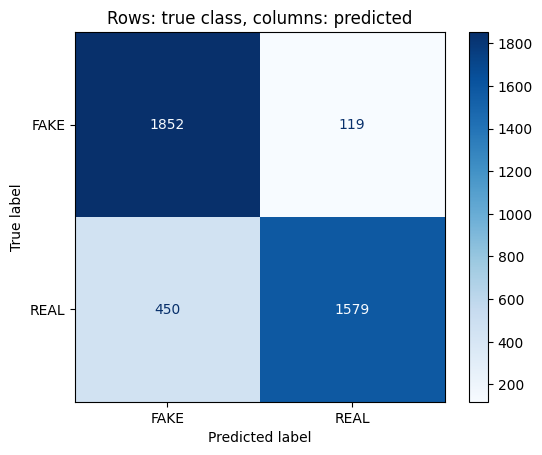

              precision    recall  f1-score   support

        FAKE       0.80      0.94      0.87      1971
        REAL       0.93      0.78      0.85      2029

    accuracy                           0.86      4000
   macro avg       0.87      0.86      0.86      4000
weighted avg       0.87      0.86      0.86      4000



In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

cm = confusion_matrix(y_true, y_preds)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title("Rows: true class, columns: predicted")
plt.show()

print(classification_report(y_true, y_preds, target_names=class_names))

## Misclassified images

errors: 569 of 4000


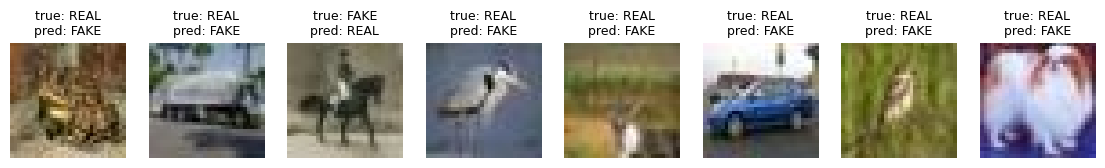

In [8]:
wrong_idx = (y_preds != y_true).nonzero().flatten().tolist()
print("errors:", len(wrong_idx), "of", len(y_true))

random.seed(0)
plt.figure(figsize=(14, 4))
for i, idx in enumerate(random.sample(wrong_idx, min(8, len(wrong_idx)))):
    img, label = test_data[idx]
    plt.subplot(1, 8, i + 1)
    plt.imshow(img.permute(1, 2, 0), interpolation="nearest")
    plt.title(f"true: {class_names[label]}\npred: {class_names[y_preds[idx]]}", fontsize=9)
    plt.axis(False)
plt.show()

## Experiment: more filters (10 → 32)

In [9]:
torch.manual_seed(42)
model_1 = TinyVGG(input_shape=3, hidden_units=32, output_shape=len(class_names)).to(device)
optimizer_1 = torch.optim.Adam(params=model_1.parameters(), lr=0.001)

start = timer()
model_1_results = train(model_1, train_dataloader, test_dataloader, loss_fn, optimizer_1, epochs=5, device=device)
model_1_time = timer() - start

epoch 0: train loss 0.4548, acc 77.3% | test loss 0.3694, acc 83.9%
epoch 1: train loss 0.3115, acc 86.9% | test loss 0.2997, acc 86.5%
epoch 2: train loss 0.2617, acc 89.1% | test loss 0.2481, acc 89.8%
epoch 3: train loss 0.2294, acc 90.8% | test loss 0.2328, acc 90.3%
epoch 4: train loss 0.2073, acc 91.8% | test loss 0.2217, acc 91.1%


In [10]:
import pandas as pd

def n_params(model):
    return sum(p.numel() for p in model.parameters())

pd.DataFrame({
    "model": ["TinyVGG, 10 filters", "TinyVGG, 32 filters"],
    "params": [n_params(model_0), n_params(model_1)],
    "test acc, %": [round(test_step(model_0, test_dataloader, loss_fn, accuracy_fn, device)[1], 1),
                    round(model_1_results["test_acc"][-1], 1)],
    "train time, s": [None if model_0_time is None else round(model_0_time), round(model_1_time)],
})

,model,params,"test acc, %","train time, s"
0,"TinyVGG, 10 filters",4292,85.8,142
1,"TinyVGG, 32 filters",32738,91.1,321
